In [3]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Raíz del repo (funciona si el notebook está en la raíz o en notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))

DATA = ROOT / "data" / "Online_Retail.xlsx"
FIG = ROOT / "figures"
TAB = ROOT / "tables"
FIG.mkdir(exist_ok=True)
TAB.mkdir(exist_ok=True)

# Semillas documentadas (una por escenario/experimento)
SEED_BASE = 2026

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110
print("Listo:", DATA.exists())

Listo: True


# Parte 0: Procesos simulados

In [4]:
def simular_ar1(n=300, c=0.0, phi=0.0, sigma=1.0, burn_in=200, rng=None):
    """Simula un AR(1) con Y_0 = 0 y descarta los primeros burn_in pasos."""
    rng = rng or np.random.default_rng()
    total = n + burn_in
    eps = rng.normal(0, sigma, total)
    y = np.zeros(total)
    for t in range(1, total):
        y[t] = c + phi * y[t-1] + eps[t]
    return y[burn_in:]


def simular_ar1_reps(reps, n=300, c=0.0, phi=0.0, sigma=1.0, burn_in=200, rng=None):
    """Simula `reps` réplicas a la vez. Devuelve una matriz (reps, n)."""
    rng = rng or np.random.default_rng()
    total = n + burn_in
    eps = rng.normal(0, sigma, size=(reps, total))
    y = np.zeros((reps, total))
    for t in range(1, total):
        y[:, t] = c + phi * y[:, t-1] + eps[:, t]
    return y[:, burn_in:]


def acf_manual(y, k):
    """Autocorrelación muestral r_k (k >= 1)."""
    y = np.asarray(y, dtype=float)
    d = y - y.mean()
    return np.sum(d[k:] * d[:-k]) / np.sum(d**2)


def acf_vec(y, kmax):
    """r_1, ..., r_kmax."""
    return np.array([acf_manual(y, k) for k in range(1, kmax + 1)])

In [5]:
from statsmodels.tsa.stattools import acf

y = simular_ar1(phi=0.5, rng=np.random.default_rng(SEED_BASE))
print(len(y))
print(acf_manual(y, 1), acf(y, nlags=1, fft=False)[1])

300
0.5857748974397385 0.5857748974397387


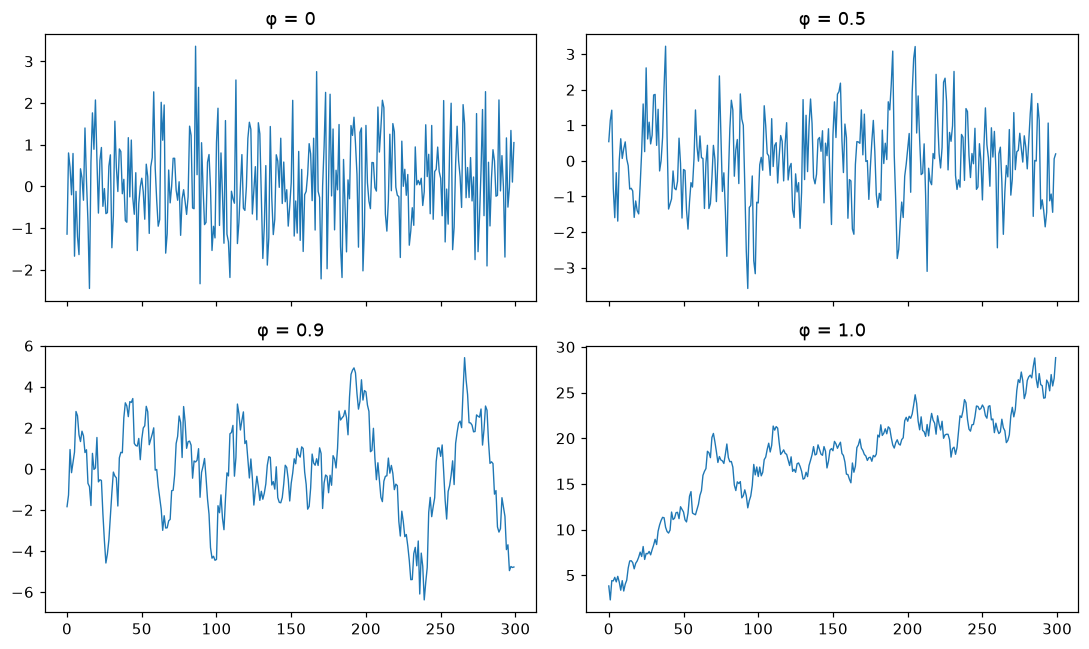

In [6]:
phis = [0, 0.5, 0.9, 1.0]
N, REPS = 300, 5000

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for i, (phi, ax) in enumerate(zip(phis, axes.ravel())):
    y = simular_ar1(n=N, phi=phi, rng=np.random.default_rng(SEED_BASE + 100 + i))
    ax.plot(y, lw=0.9)
    ax.set_title(f"φ = {phi}")
fig.tight_layout()
fig.savefig(FIG / "p0_realizaciones.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
def r_k_matriz(Y, k):
    """r_k para cada fila (réplica) de Y."""
    d = Y - Y.mean(axis=1, keepdims=True)
    return (d[:, k:] * d[:, :-k]).sum(axis=1) / (d**2).sum(axis=1)


def phi_ols_matriz(Y):
    """Estimado OLS de phi (con intercepto) para cada fila de Y."""
    x, z = Y[:, :-1], Y[:, 1:]            # y_{t-1} y y_t
    xc = x - x.mean(axis=1, keepdims=True)
    zc = z - z.mean(axis=1, keepdims=True)
    return (xc * zc).sum(axis=1) / (xc**2).sum(axis=1)

In [8]:
filas = []
for i, phi in enumerate(phis):
    rng = np.random.default_rng(SEED_BASE + i)     # semilla distinta por escenario
    Y = simular_ar1_reps(REPS, n=N, phi=phi, rng=rng)
    r1, r5, ph = r_k_matriz(Y, 1), r_k_matriz(Y, 5), phi_ols_matriz(Y)
    p = (np.abs(r1) > 1.96 / np.sqrt(N)).mean()
    filas.append({
        "phi": phi,
        "prom_r1": r1.mean(),  "ee_r1": r1.std(ddof=1) / np.sqrt(REPS),
        "prom_r5": r5.mean(),  "ee_r5": r5.std(ddof=1) / np.sqrt(REPS),
        "phi^5": phi**5,
        "rechazo_r1": p,       "ee_rechazo": np.sqrt(p * (1 - p) / REPS),
        "prom_phi_ols": ph.mean(), "ee_phi_ols": ph.std(ddof=1) / np.sqrt(REPS),
    })

tabla02 = pd.DataFrame(filas).round(4)
tabla02.to_csv(TAB / "p0_tabla_02.csv", index=False)
tabla02

,phi,prom_r1,ee_r1,prom_r5,ee_r5,phi^5,rechazo_r1,ee_rechazo,prom_phi_ols,ee_phi_ols
0,0.0,-0.0039,0.0008,-0.0028,0.0008,0.0000,0.05,0.0031,-0.0039,0.0008
1,0.5,0.4892,0.0007,0.0199,0.0010,0.0312,1.00,0.0000,0.4909,0.0007
2,0.9,0.8839,0.0004,0.5339,0.0014,0.5905,1.00,0.0000,0.8871,0.0004
3,1.0,0.9758,0.0002,0.8835,0.0009,1.0000,1.00,0.0000,0.9824,0.0002


In [9]:
def simular_media(m, reps, sigma=1.0, rng=None):
    """Y_t = m_t + eps_t, replicado `reps` veces. Devuelve (reps, len(m))."""
    rng = rng or np.random.default_rng()
    return m + rng.normal(0, sigma, size=(reps, len(m)))

t = np.arange(1, N + 1)
procesos = {
    "(a) tendencia": 2 * t / 300,
    "(b) semanal":   np.where(t % 7 == 6, -1.5, 0.25),
}

def resumen_04(nombre, Y):
    r1, r7 = r_k_matriz(Y, 1), r_k_matriz(Y, 7)
    p = (np.abs(r1) > 1.96 / np.sqrt(N)).mean()
    return {
        "proceso": nombre,
        "prom_r1": r1.mean(), "ee_r1": r1.std(ddof=1) / np.sqrt(REPS),
        "rechazo_r1": p,      "ee_rechazo": np.sqrt(p * (1 - p) / REPS),
        "prom_r7": r7.mean(), "ee_r7": r7.std(ddof=1) / np.sqrt(REPS),
    }

filas04 = [resumen_04("phi=0 (ref.)",
                      simular_ar1_reps(REPS, n=N, phi=0.0, rng=np.random.default_rng(SEED_BASE + 0)))]
for j, (nombre, m) in enumerate(procesos.items()):
    Y = simular_media(m, REPS, rng=np.random.default_rng(SEED_BASE + 10 + j))
    filas04.append(resumen_04(nombre, Y))

tabla04 = pd.DataFrame(filas04).round(4)
tabla04.to_csv(TAB / "p0_tabla_04.csv", index=False)
tabla04

,proceso,prom_r1,ee_r1,rechazo_r1,ee_rechazo,prom_r7,ee_r7
0,phi=0 (ref.),-0.0039,0.0008,0.0500,0.0031,-0.0017,0.0008
1,(a) tendencia,0.2446,0.0008,0.9834,0.0018,0.2297,0.0008
2,(b) semanal,-0.0476,0.0007,0.1050,0.0043,0.2642,0.0008


In [10]:
from scipy.stats import chi2
from statsmodels.stats.diagnostic import acorr_ljungbox

def ljung_box_matriz(Y, m=10):
    """Q(m) de Ljung-Box para cada fila (réplica) de Y."""
    n_reps, n = Y.shape
    Q = np.zeros(n_reps)
    for k in range(1, m + 1):
        rk = r_k_matriz(Y, k)
        Q += (rk**2) / (n - k)
    return n * (n + 2) * Q

def tasa_rechazo_lb(Y, m=10, nivel=0.05):
    """Fracción de réplicas con Q(m) > valor crítico de una chi-cuadrado(m)."""
    crit = chi2.ppf(1 - nivel, df=m)
    return (ljung_box_matriz(Y, m) > crit).mean()

In [11]:
escenarios = {
    "phi=0":         simular_ar1_reps(REPS, n=N, phi=0.0, rng=np.random.default_rng(SEED_BASE + 0)),
    "(a) tendencia": simular_media(procesos["(a) tendencia"], REPS, rng=np.random.default_rng(SEED_BASE + 10)),
    "(b) semanal":   simular_media(procesos["(b) semanal"],   REPS, rng=np.random.default_rng(SEED_BASE + 11)),
}
print({k: v.shape for k, v in escenarios.items()})

{'phi=0': (5000, 300), '(a) tendencia': (5000, 300), '(b) semanal': (5000, 300)}


In [12]:
y = escenarios["(b) semanal"][0]
Q_mio = ljung_box_matriz(y.reshape(1, -1), 10)[0]
lb = acorr_ljungbox(y, lags=[10])
print(Q_mio, lb["lb_stat"].iloc[0])

61.055533259853945 61.055533259853966


In [13]:
M2 = int(round(np.log(N)))        # ln(300) ≈ 5.7 -> 6
filas05 = [{"proceso": nombre,
            "rechazo_LB10": tasa_rechazo_lb(Y, 10),
            f"rechazo_LB{M2}": tasa_rechazo_lb(Y, M2)}
           for nombre, Y in escenarios.items()]
tabla05 = pd.DataFrame(filas05).round(4)
tabla05.to_csv(TAB / "p0_tabla_05.csv", index=False)
tabla05

,proceso,rechazo_LB10,rechazo_LB6
0,phi=0,0.0612,0.0600
1,(a) tendencia,1.0000,1.0000
2,(b) semanal,0.9514,0.1948


# Parte 1: Limpieza

In [14]:
raw = pd.read_excel(DATA, dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": str})

print("filas:", len(raw))
print("facturas:", raw["InvoiceNo"].nunique())
print("productos (StockCode):", raw["StockCode"].nunique())
print("clientes:", raw["CustomerID"].nunique())
print("fracción sin CustomerID:", round(raw["CustomerID"].isna().mean(), 4))

filas: 541909
facturas: 25900
productos (StockCode): 4070
clientes: 4372
fracción sin CustomerID: 0.2493


In [15]:
# (a) duplicados exactos
print("(a) duplicadas:", raw.duplicated().sum())

# (b) facturas que no empiezan con dígito
no_dig = raw[~raw["InvoiceNo"].str[0].str.isdigit()]
print("\n(b) prefijos:\n", no_dig["InvoiceNo"].str[0].value_counts())
print(no_dig[no_dig["InvoiceNo"].str[0] != "C"].head(3))

# (c) StockCode que no empieza con 5 dígitos
nd = raw[~raw["StockCode"].str.match(r"^\d{5}")]
resumen_c = (nd.groupby("StockCode")
               .agg(n=("Description", "size"),
                    descripcion=("Description", lambda s: s.dropna().iloc[0] if s.notna().any() else None),
                    monto=("UnitPrice", "sum"))
               .sort_values("n", ascending=False))
print("\n(c) códigos no estándar:\n", resumen_c.head(25))

# (d) precios <= 0
print("\n(d) precio <= 0:", (raw["UnitPrice"] <= 0).sum(), "| negativos:", (raw["UnitPrice"] < 0).sum())

# (e) cantidades negativas en facturas que NO son cancelaciones
neg = raw[(raw["Quantity"] < 0) & ~raw["InvoiceNo"].str.startswith("C")]
print("\n(e) cantidad negativa sin 'C':", len(neg))
print(neg["Description"].value_counts().head(8))
print(neg["UnitPrice"].describe())

# (f) sin CustomerID
sin_cli = raw[raw["CustomerID"].isna()]
print("\n(f) sin CustomerID:", len(sin_cli),
      "| de ellas, cancelaciones:", sin_cli["InvoiceNo"].str.startswith("C").sum())

(a) duplicadas: 5268

(b) prefijos:
 InvoiceNo
C    9288
A       3
Name: count, dtype: int64
       InvoiceNo StockCode      Description  Quantity         InvoiceDate  \
299982   A563185         B  Adjust bad debt         1 2011-08-12 14:50:00   
299983   A563186         B  Adjust bad debt         1 2011-08-12 14:51:00   
299984   A563187         B  Adjust bad debt         1 2011-08-12 14:52:00   

        UnitPrice CustomerID         Country  
299982   11062.06        NaN  United Kingdom  
299983  -11062.06        NaN  United Kingdom  
299984  -11062.06        NaN  United Kingdom  

(c) códigos no estándar:
                  n                         descripcion       monto
StockCode                                                         
POST          1256                             POSTAGE   46388.470
DOT            710                      DOTCOM POSTAGE  206252.060
M              571                              Manual  214448.410
C2             144                            CA

In [16]:
from pathlib import Path
Path("src").mkdir(exist_ok=True)

In [21]:
%%writefile src/limpiar.py
import pandas as pd

# StockCode que NO son productos (cobros, envíos, ajustes y comisiones).
NO_PRODUCTO = {
    "POST", "DOT", "C2",                   # envíos / carriage / postage
    "M",                                   # ajustes manuales
    "D",                                   # descuentos
    "S",                                   # muestras
    "BANK CHARGES", "AMAZONFEE", "CRUK",   # cargos y comisiones
    "B",                                   # ajuste de deuda incobrable
}


def _ventas_anuladas_manualmente(x):
    """Ventas que una cancelación manual ('M') anuló: mismo cliente, mismo día
    y mismo monto. La regla de códigos no producto elimina la cancelación 'M';
    sin esta regla quedaría la venta 'huérfana' inflando la serie diaria."""
    cm = x[(x["StockCode"] == "M")
           & x["InvoiceNo"].str.startswith("C")
           & x["CustomerID"].notna()]
    llaves = pd.MultiIndex.from_arrays(
        [cm["CustomerID"], cm["InvoiceDate"].dt.normalize(), (-cm["monto"]).round(2)])
    idx = pd.MultiIndex.from_arrays(
        [x["CustomerID"], x["InvoiceDate"].dt.normalize(), x["monto"].round(2)])
    return (pd.Series(idx.isin(llaves), index=x.index)
            & (x["monto"] > 0)
            & (x["StockCode"] != "M")
            & ~x["InvoiceNo"].str.startswith("C"))


def limpiar(df, devolver_bitacora=False):
    """Limpia Online Retail y devuelve un DataFrame.

    Conserva las filas sin CustomerID (sirven para la serie de ventas; la
    Parte 6 las excluye por su cuenta). Las cancelaciones ('C') se conservan
    porque su cantidad negativa ya resta de las ventas del día.

    Si devolver_bitacora=True, devuelve (df_limpio, bitacora), con una fila
    por regla en el orden en que se aplicaron.
    """
    d = df.copy()
    d["monto"] = d["Quantity"] * d["UnitPrice"]

    # Cada regla devuelve la máscara de filas que SE ELIMINAN.
    # El orden importa: cada regla cuenta solo lo que elimina en ese momento.
    reglas = [
        ("a) duplicados exactos",
         lambda x: x.duplicated()),
        ("b) factura con prefijo A (ajuste contable)",
         lambda x: x["InvoiceNo"].str.startswith("A")),
        ("c) venta anulada por cancelación manual (M)",
         _ventas_anuladas_manualmente),
        ("d) StockCode que no es producto",
         lambda x: x["StockCode"].isin(NO_PRODUCTO)),
        ("e) precio <= 0",
         lambda x: x["UnitPrice"] <= 0),
        ("f) cantidad negativa sin 'C'",
         lambda x: (x["Quantity"] < 0) & ~x["InvoiceNo"].str.startswith("C")),
    ]

    filas = []
    for nombre, regla in reglas:
        mask = regla(d)
        filas.append({
            "regla": nombre,
            "filas_eliminadas": int(mask.sum()),
            "monto_gbp": float(d.loc[mask, "monto"].sum()),
        })
        d = d[~mask]

    limpio = d.drop(columns="monto").reset_index(drop=True)
    if devolver_bitacora:
        return limpio, pd.DataFrame(filas)
    return limpio

Overwriting src/limpiar.py


In [23]:
df, bitacora = limpiar(raw, devolver_bitacora=True)
print(len(raw), "->", len(df))
bitacora.round(2)

541909 -> 531223


,regla,filas_eliminadas,monto_gbp
0,a) duplicados exactos,5268,21740.98
1,b) factura con prefijo A (ajuste contable),3,-11062.06
2,c) venta anulada por cancelación manual (M),17,39033.26
3,d) StockCode que no es producto,2902,-34937.51
4,e) precio <= 0,2496,0.00
5,f) cantidad negativa sin 'C',0,0.00


In [24]:
tmp = raw.assign(monto=raw["Quantity"] * raw["UnitPrice"])
top6 = tmp.loc[tmp["monto"].abs().sort_values(ascending=False).index[:6]]
top6[["InvoiceNo", "StockCode", "Description", "Quantity",
      "InvoiceDate", "UnitPrice", "CustomerID", "monto"]]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,monto
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,-168469.6
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,168469.6
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,-77183.6
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,77183.6
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098,-38970.0
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098,38970.0


In [25]:
print(pd.DataFrame({"factura": top6["InvoiceNo"].values,
                    "sobrevive": top6["InvoiceNo"].isin(df["InvoiceNo"]).values}))

dfv = df.assign(dia=df["InvoiceDate"].dt.normalize(),
                monto=df["Quantity"] * df["UnitPrice"])
venta_dia = dfv.groupby("dia")["monto"].sum()
venta_dia.loc[pd.to_datetime(["2011-01-18", "2011-06-10", "2011-12-09"])]

   factura  sobrevive
0  C581484       True
1   581483       True
2  C541433       True
3   541431       True
4  C556445      False
5   556444      False


2011-01-18    17067.28
2011-06-10    21937.45
2011-12-09    29530.26
Name: monto, dtype: float64

# Parte 2: El calendario

In [26]:
df["dia"] = df["InvoiceDate"].dt.normalize()
df["monto"] = df["Quantity"] * df["UnitPrice"]
venta = df.groupby("dia")["monto"].sum()

calendario = pd.date_range(venta.index.min(), venta.index.max(), freq="D")
print("primer día:", venta.index.min().date(), "| último día:", venta.index.max().date())
print("días calendario:", len(calendario), "| con transacciones:", len(venta))

primer día: 2010-12-01 | último día: 2011-12-09
días calendario: 374 | con transacciones: 305


In [27]:
faltan = calendario.difference(venta.index)
tabla_faltan = pd.DataFrame({"fecha": faltan, "dia_semana": faltan.day_name()})
print(tabla_faltan["dia_semana"].value_counts())
tabla_faltan[tabla_faltan["dia_semana"] != "Saturday"]

dia_semana
Saturday     53
Monday        6
Friday        4
Sunday        3
Tuesday       1
Wednesday     1
Thursday      1
Name: count, dtype: int64


,fecha,dia_semana
3,2010-12-24,Friday
5,2010-12-26,Sunday
6,2010-12-27,Monday
7,2010-12-28,Tuesday
8,2010-12-29,Wednesday
9,2010-12-30,Thursday
10,2010-12-31,Friday
12,2011-01-02,Sunday
13,2011-01-03,Monday
29,2011-04-22,Friday


In [28]:
ultimo = df[df["dia"] == venta.index.max()]
print(ultimo["InvoiceDate"].min(), "->", ultimo["InvoiceDate"].max(), "|", len(ultimo), "filas")

hora_cierre = df.groupby("dia")["InvoiceDate"].max().dt.hour   # a qué hora cierra cada día
print(hora_cierre.describe())
venta.tail(3)

2011-12-09 08:39:00 -> 2011-12-09 12:50:00 | 1617 filas
count    305.000000
mean      17.055738
std        1.216732
min       12.000000
25%       16.000000
50%       17.000000
75%       17.000000
max       20.000000
Name: InvoiceDate, dtype: float64


dia
2011-12-07    72571.10
2011-12-08    76493.97
2011-12-09    29530.26
Name: monto, dtype: float64

In [29]:
# Clasificación de los días sin transacciones
nombres = {
    "2010-12-24": "Cierre de fin de año", "2010-12-26": "Boxing Day (domingo)",
    "2010-12-27": "Feriado sustituto de Navidad", "2010-12-28": "Feriado sustituto de Boxing Day",
    "2010-12-29": "Cierre de fin de año", "2010-12-30": "Cierre de fin de año",
    "2010-12-31": "Cierre de fin de año", "2011-01-02": "Domingo del cierre de fin de año",
    "2011-01-03": "Feriado sustituto de Año Nuevo", "2011-04-22": "Viernes Santo",
    "2011-04-24": "Domingo de Pascua", "2011-04-25": "Lunes de Pascua",
    "2011-04-29": "Boda real (feriado especial)", "2011-05-02": "Early May bank holiday",
    "2011-05-30": "Spring bank holiday", "2011-08-29": "Summer bank holiday",
}
tabla_faltan["tipo"] = [
    "Sábado (cierre semanal)" if d.dayofweek == 5 else nombres.get(d.strftime("%Y-%m-%d"), "SIN CLASIFICAR")
    for d in tabla_faltan["fecha"]
]
print(tabla_faltan["tipo"].value_counts())
tabla_faltan.to_csv(TAB / "p2_dias_sin_ventas.csv", index=False)

# Serie para el resto de la tarea: calendario completo, días cerrados = NaN, sin el último día
ultimo_dia = venta.index.max()
serie = venta.reindex(calendario)
serie = serie.loc[serie.index < ultimo_dia]
print(len(serie), "días |", serie.isna().sum(), "faltantes |", serie.notna().sum(), "con ventas")

tipo
Sábado (cierre semanal)             53
Cierre de fin de año                 4
Boxing Day (domingo)                 1
Feriado sustituto de Navidad         1
Feriado sustituto de Boxing Day      1
Domingo del cierre de fin de año     1
Feriado sustituto de Año Nuevo       1
Viernes Santo                        1
Domingo de Pascua                    1
Lunes de Pascua                      1
Boda real (feriado especial)         1
Early May bank holiday               1
Spring bank holiday                  1
Summer bank holiday                  1
Name: count, dtype: int64
373 días | 69 faltantes | 304 con ventas


# Parte 3: Tendencia, estacionalidad y autocorrelación

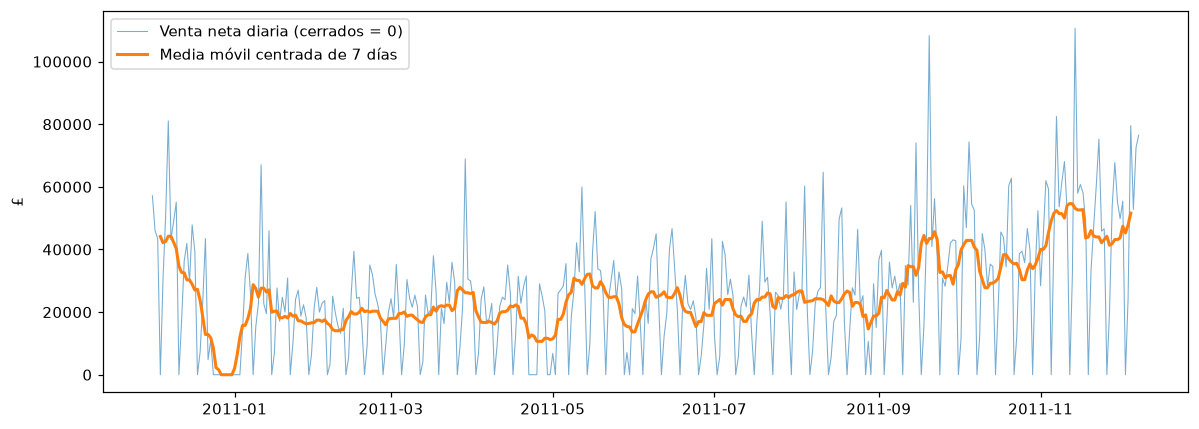

In [32]:
## 3.1 Tendencia
serie_cero = serie.fillna(0)                          # aquí sí: cerrados = 0
ma7 = serie_cero.rolling(window=7, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(serie_cero.index, serie_cero.values, lw=0.7, alpha=0.6,
        label="Venta neta diaria (cerrados = 0)")
ax.plot(ma7.index, ma7.values, lw=2, label="Media móvil centrada de 7 días")
ax.set_ylabel("£")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "p3_media_movil.png", dpi=200, bbox_inches="tight")
plt.show()

           indice_estacional
Lunes                 1.1711
Martes                1.5479
Miércoles             1.2273
Jueves                1.5653
Viernes               1.1100
Domingo               0.5767
Promedio de los índices: 1.1997


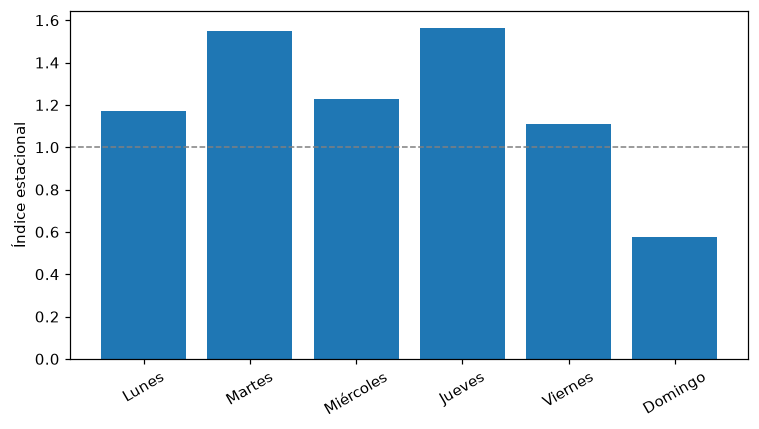

In [35]:
## 3.2 Estacionalidad
fin_train = pd.Timestamp("2011-09-30")

# Entrenamiento: calendario hasta el 30 de septiembre, cerrados = 0 para la media móvil
serie_cero_tr = serie_cero[serie_cero.index <= fin_train]
ma7_tr = serie_cero_tr.rolling(window=7, center=True).mean()   # los últimos 3 días quedan NaN

# Cociente y_t / MA_t solo en días abiertos
abiertos_tr = serie[serie.index <= fin_train].dropna()
cociente = (abiertos_tr / ma7_tr.reindex(abiertos_tr.index)).dropna()

# Índice estacional = promedio del cociente por día de la semana
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
indice = cociente.groupby(cociente.index.dayofweek).mean()
indice.index = [dias[i] for i in indice.index]

tabla_indice = indice.round(4).rename("indice_estacional").to_frame()
tabla_indice.to_csv(TAB / "p3_indice_estacional.csv")
print(tabla_indice)
print("Promedio de los índices:", round(indice.mean(), 4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(indice.index, indice.values)
ax.axhline(1, ls="--", lw=1, color="gray")
ax.set_ylabel("Índice estacional")
plt.xticks(rotation=30)
fig.tight_layout()
fig.savefig(FIG / "p3_indice_estacional.png", dpi=200, bbox_inches="tight")
plt.show()

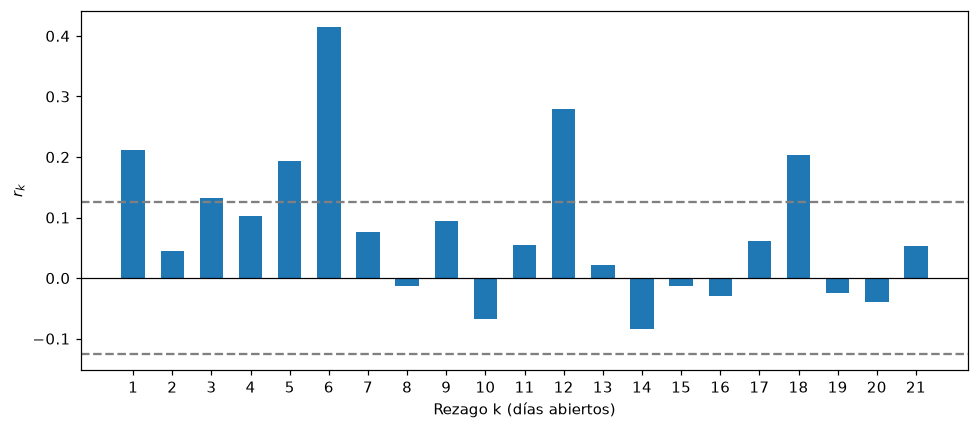

n = 245 | banda ± 0.1252
rezagos fuera de bandas: [1, 3, 5, 6, 12, 18] | total: 6
r1 = 0.212 | pasa la prueba de retardo 1: False
pico en k = 6 | r = 0.4142
Q(6) = 71.53 | p-valor = 1.98e-13
Q(12) = 97.57 | p-valor = 1.66e-15
      lb_stat     lb_pvalue
6   71.533842  1.980748e-13
12  97.570513  1.663324e-15


In [36]:
## 3.3 Estacionalidad
y_tr = serie[serie.index <= fin_train].dropna().values     # días abiertos del entrenamiento
n_tr = len(y_tr)
r = acf_vec(y_tr, 21)
banda = 1.96 / np.sqrt(n_tr)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, 22), r, width=0.6)
ax.axhline(banda, ls="--", color="gray")
ax.axhline(-banda, ls="--", color="gray")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Rezago k (días abiertos)")
ax.set_ylabel("$r_k$")
ax.set_xticks(range(1, 22))
fig.tight_layout()
fig.savefig(FIG / "p3_acf_ventas.png", dpi=200, bbox_inches="tight")
plt.show()

fuera = np.where(np.abs(r) > banda)[0] + 1
print("n =", n_tr, "| banda ±", round(banda, 4))
print("rezagos fuera de bandas:", fuera.tolist(), "| total:", len(fuera))
print("r1 =", round(r[0], 4), "| pasa la prueba de retardo 1:", abs(r[0]) <= banda)
print("pico en k =", int(np.argmax(r)) + 1, "| r =", round(r.max(), 4))

# Ljung-Box a mano, verificado con statsmodels
def ljung_box_Q(y, m):
    n = len(y)
    rk = acf_vec(y, m)
    return n * (n + 2) * np.sum(rk**2 / (n - np.arange(1, m + 1)))

for m in (6, 12):
    Q = ljung_box_Q(y_tr, m)
    print(f"Q({m}) = {Q:.2f} | p-valor = {chi2.sf(Q, m):.3g}")
print(acorr_ljungbox(y_tr, lags=[6, 12]))

# Parte 4: Del AR(1) al SARIMA

Lun    27215.8
Mar    35170.0
Mié    27838.7
Jue    35428.7
Vie    26261.6
Dom    13716.7
dtype: float64


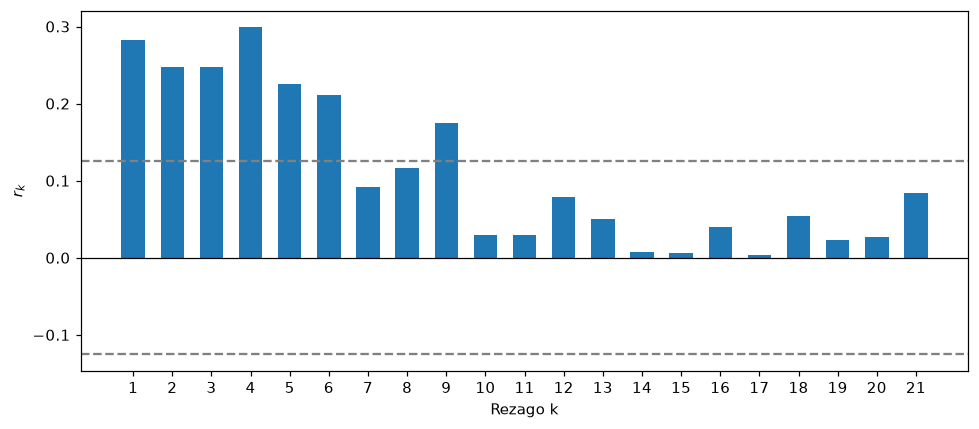

n = 245 | r1..r6 = [0.282 0.247 0.248 0.299 0.225 0.212]
rezagos fuera de bandas: [1, 2, 3, 4, 5, 6, 9]
Q(6) = 96.91 | p = 1.11e-18
Q(12) = 112.43 | p = 1.98e-18


In [37]:
## 4.1

import statsmodels.api as sm

def graficar_acf(x, kmax=21, archivo=None):
    r = acf_vec(x, kmax)
    banda = 1.96 / np.sqrt(len(x))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(range(1, kmax + 1), r, width=0.6)
    ax.axhline(banda, ls="--", color="gray")
    ax.axhline(-banda, ls="--", color="gray")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Rezago k")
    ax.set_ylabel("$r_k$")
    ax.set_xticks(range(1, kmax + 1))
    fig.tight_layout()
    if archivo:
        fig.savefig(FIG / archivo, dpi=200, bbox_inches="tight")
    plt.show()
    fuera = (np.where(np.abs(r) > banda)[0] + 1).tolist()
    return r, banda, fuera

# Días abiertos del entrenamiento y sus indicadoras de día (sin intercepto)
y_ent = serie[serie.index <= fin_train].dropna()
X = pd.get_dummies(y_ent.index.dayofweek).astype(float)
X.columns = ["Lun", "Mar", "Mié", "Jue", "Vie", "Dom"]

ols = sm.OLS(y_ent.values, X.values).fit()
e = ols.resid                                     # residuos e_t
print(pd.Series(ols.params, index=X.columns).round(1))

r_e, banda_e, fuera_e = graficar_acf(e, 21, "p4_acf_ols.png")
print("n =", len(e), "| r1..r6 =", r_e[:6].round(3))
print("rezagos fuera de bandas:", fuera_e)
for m in (6, 12):
    Q = ljung_box_Q(e, m)
    print(f"Q({m}) = {Q:.2f} | p = {chi2.sf(Q, m):.3g}")

c = -100.86 | phi = 0.2843 (e.e. 0.0611)


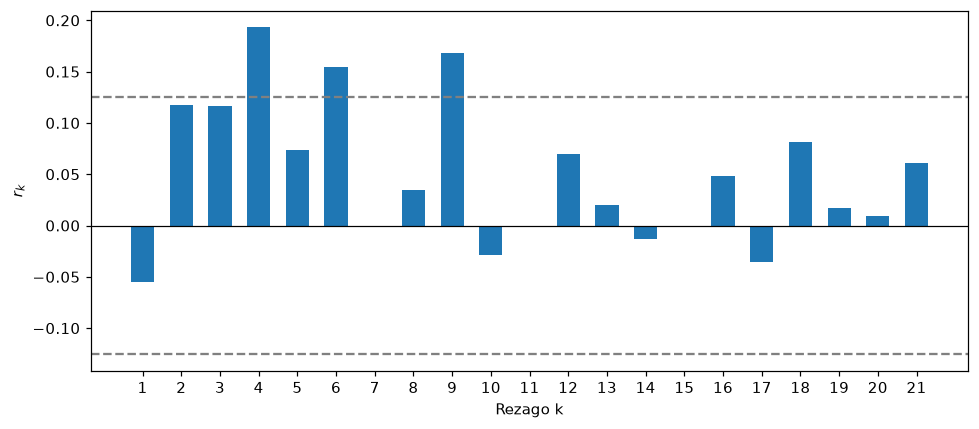

n = 244 | r1..r6 = [-0.055  0.118  0.116  0.193  0.074  0.154]
rezagos fuera de bandas: [4, 6, 9]
Q(6) = 24.26 | p (g.l. = m-1) = 0.000194
Q(12) = 33.23 | p (g.l. = m-1) = 0.000482


In [39]:
## 4.2

ar = sm.OLS(e[1:], sm.add_constant(e[:-1])).fit()
c_hat, phi_hat = ar.params
u = ar.resid                                       # u_t = e_t - c - phi * e_{t-1}
print(f"c = {c_hat:.2f} | phi = {phi_hat:.4f} (e.e. {ar.bse[1]:.4f})")

r_u, banda_u, fuera_u = graficar_acf(u, 21, "p4_acf_ar1.png")
print("n =", len(u), "| r1..r6 =", r_u[:6].round(3))
print("rezagos fuera de bandas:", fuera_u)
for m in (6, 12):
    Q = ljung_box_Q(u, m)
    print(f"Q({m}) = {Q:.2f} | p (g.l. = m-1) = {chi2.sf(Q, m - 1):.3g}")

In [40]:
## 4.3

from statsmodels.tsa.statespace.sarimax import SARIMAX

ly = np.log(y_ent.values)

# S1: SARIMA(1,0,0)(1,0,0)_6 con constante
mod1 = SARIMAX(ly, order=(1, 0, 0), seasonal_order=(1, 0, 0, 6), trend="c")
res1_a = mod1.fit(disp=False)                       # maxiter por defecto
print("S1 convergió (por defecto):", res1_a.mle_retvals["converged"])
print(res1_a.params.round(4))

res1 = mod1.fit(disp=False, maxiter=500)
print("S1 convergió (maxiter=500):", res1.mle_retvals["converged"])
print(res1.params.round(4))
print("log-verosimilitud antes/después:", round(res1_a.llf, 2), round(res1.llf, 2))

# S2: SARIMA(0,1,1)(0,1,1)_6 sin constante
mod2 = SARIMAX(ly, order=(0, 1, 1), seasonal_order=(0, 1, 1, 6), trend="n")
res2 = mod2.fit(disp=False, maxiter=500)
print("\nS2 convergió:", res2.mle_retvals["converged"])
print(res2.summary().tables[1])

C:\Users\noele\bi-tarea4-series-de-tiempo\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


S1 convergió (por defecto): False
[0.8901 0.1387 0.8951 0.2638]
S1 convergió (maxiter=500): True
[4.2732 0.1272 0.5165 0.2189]
log-verosimilitud antes/después: -187.0 -162.47

S2 convergió: True
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9092      0.034    -26.873      0.000      -0.975      -0.843
ma.S.L6       -0.6836      0.051    -13.449      0.000      -0.783      -0.584
sigma2         0.2139      0.016     13.514      0.000       0.183       0.245


In [43]:
## 4.4

res_s1 = res1.resid
res_s2 = res2.resid[7:]            # (1-B)(1-B^6) consume 7 observaciones: son artefactos

for nombre, rs in [("S1", res_s1), ("S2", res_s2)]:
    for m in (6, 12):
        Q = ljung_box_Q(rs, m)
        print(f"{nombre}: Q({m}) = {Q:.2f} | p (g.l. = m-2) = {chi2.sf(Q, m - 2):.3g}")

S1: Q(6) = 9.64 | p (g.l. = m-2) = 0.0469
S1: Q(12) = 24.73 | p (g.l. = m-2) = 0.00589
S2: Q(6) = 3.60 | p (g.l. = m-2) = 0.462
S2: Q(12) = 9.26 | p (g.l. = m-2) = 0.507
